# Assignment 2: Diabetes Classification

**Workflow:** UNDERSTAND → EDA → SPLIT → PREPARE → FIT → PREDICT → EVALUATE → INTERPRET

For the important parts of the analysis, think: **QUESTION → EVIDENCE → DECISION**

Reminders:
- Keep TEST protected.
- Association is not causation.
- Accuracy is not enough by itself.
- Do **not** remove duplicate rows (`drop_duplicates()`), and no missing-value imputation is needed.

## Setup – Imports and loading the data

- Import the libraries we need (pandas, numpy, matplotlib/seaborn, scikit-learn).
- Load `diabetes_binary_classification_data.csv` into a DataFrame.
- Take a first look at the data (`head()`, `shape`, `info()`).

In [24]:
from locale import normalize

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, r2_score


df = pd.read_csv("diabetes_binary_classification_data.csv")
print(df.shape)
df.head()


(253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## Step 1 – Understand the data

- Identify the input features **X** and the target **y**.
- Explain what class 0 and class 1 mean.
- Check the number and proportion of observations in each class.
- Choose three features of different types and briefly explain what their values mean (use the *Understanding the Dataset* guide).

*Related questions: Q1, Q2*

In [25]:
# Separate input features and target
X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)


Input features:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target:
Diabetes_binary


In [41]:
# Count observations in each class
class_counts = y.value_counts().sort_index()

# Calculate percentages
class_percentages = y.value_counts(normalize=True).sort_index() * 100

# Create a summary table
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

# Display formatted table
display(class_distribution)

,Count,Percentage (%)
Diabetes_binary,,
0.0,218334,86.07
1.0,35346,13.93


In [42]:
# Summary of three different feature types
feature_summary = pd.DataFrame({
    "Feature": ["BMI", "HighBP", "GenHlth"],
    "Type": ["Numerical", "Binary", "Ordinal"],
    "Values": [
        f"{df['BMI'].min():.0f} - {df['BMI'].max():.0f}",
        "0, 1",
        "1, 2, 3, 4, 5"
    ],
    "Meaning": [
        "Body Mass Index",
        "0 = No, 1 = Yes",
        "1 = Excellent, 5 = Poor"
    ]
})

display(feature_summary)

,Feature,Type,Values,Meaning
0,BMI,Numerical,12 - 98,Body Mass Index
1,HighBP,Binary,"0, 1","0 = No, 1 = Yes"
2,GenHlth,Ordinal,"1, 2, 3, 4, 5","1 = Excellent, 5 = Poor"


Class 0 and class 1 is the two possible values to the target variable `Diabetes_binary` can take, that is, what the model should predict (Y). The other features like BMI, HighBP or Age, is input features (X). The dataset is not balanced since only 13.9% is in class 1.

- BMI is the Body Mass Index, it is a measurement of body weight in correlation to height. It is a numerical value and in the dataset it starts at 12 and ends at 98.
- Age is divided into age groups.

 ## Step 2 – Explore the data (EDA)

Investigate **all** input features and their relationship with `Diabetes_binary`. Choose plots/tables that fit the feature type:

- **Numerical features** (`BMI`, `MentHlth`, `PhysHlth`): examine their distributions and compare them between the two target classes.
- **Binary categorical features** (`HighBP`, `HighChol`, `CholCheck`, `Smoker`, `Stroke`, `HeartDiseaseorAttack`, `PhysActivity`, `Fruits`, `Veggies`, `HvyAlcoholConsump`, `AnyHealthcare`, `NoDocbcCost`, `DiffWalk`, `Sex`): examine counts/proportions and compare the proportion of `Diabetes_binary` across the two categories.
- **Ordered categorical features** (`GenHlth`, `Age`, `Education`, `Income`): examine how the proportion of `Diabetes_binary` changes across the ordered categories.

Use loops or functions rather than repeating identical code. For the 3–5 most informative results: state the question, show the evidence, explain what you observe, and what you can and cannot conclude.

*Related question: Q3*

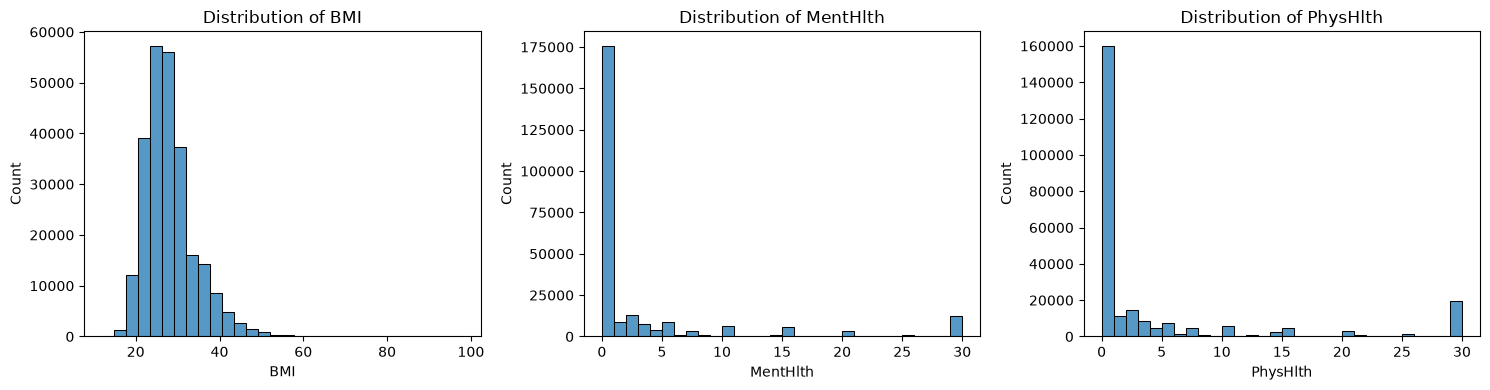

In [32]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, numerical_features):
    sns.histplot(data=df, x=feature, bins=30, ax=ax)
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

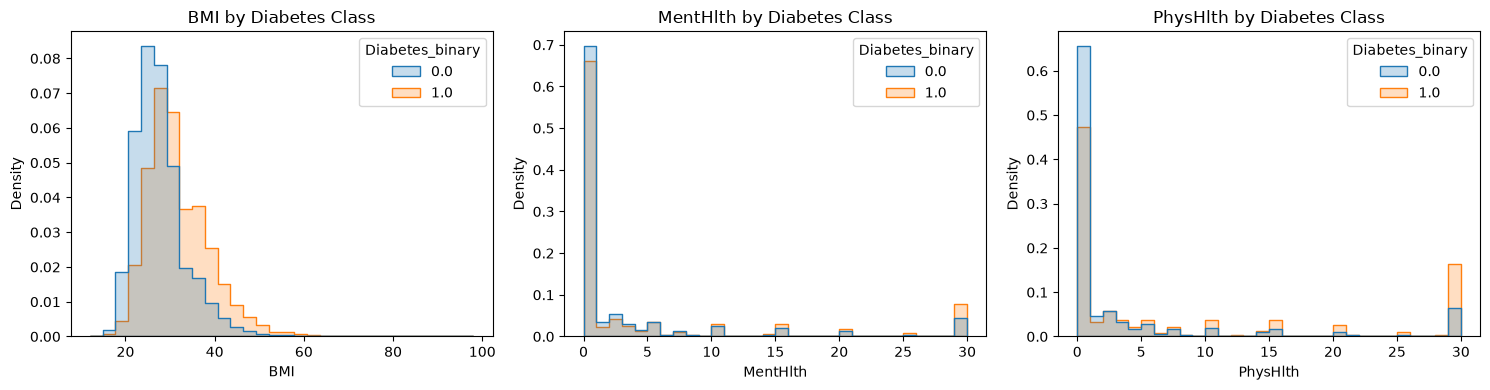

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        hue="Diabetes_binary",
        bins=30,
        stat="density",
        common_norm=False,
        element="step",
        ax=ax
    )

    ax.set_title(f"{feature} by Diabetes Class")
    ax.set_xlabel(feature)
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

In [36]:
# Summary statistics for each diabetes class
summary = df.groupby("Diabetes_binary")[numerical_features].agg(
    ["mean", "median", "std"]
)

display(summary.round(2))

BMI              MentHlth              PhysHlth         \
                  mean median   std     mean median   std     mean median   
Diabetes_binary                                                             
0.0              27.81   27.0  6.29     2.98    0.0  7.11     3.64    0.0   
1.0              31.94   31.0  7.36     4.46    0.0  8.95     7.95    1.0   

                        
                   std  
Diabetes_binary         
0.0               8.06  
1.0              11.30

In [39]:
# Binary categorical features
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

# Calculate diabetes proportion for each category
binary_results = []

for feature in binary_features:
    for value in [0, 1]:
        subset = df[df[feature] == value]

        binary_results.append({
            "Feature": feature,
            "Category": value,
            "Count": len(subset),
            "Diabetes (%)": round(
                subset["Diabetes_binary"].mean() * 100, 2
            )
        })

binary_summary = pd.DataFrame(binary_results)

display(binary_summary)

,Feature,Category,Count,Diabetes (%)
0,HighBP,0,144851,6.04
1,HighBP,1,108829,24.45
2,HighChol,0,146089,7.98
3,HighChol,1,107591,22.01
4,CholCheck,0,9470,2.54
5,CholCheck,1,244210,14.37
6,Smoker,0,141257,12.06
7,Smoker,1,112423,16.29
8,Stroke,0,243388,13.18
9,Stroke,1,10292,31.75


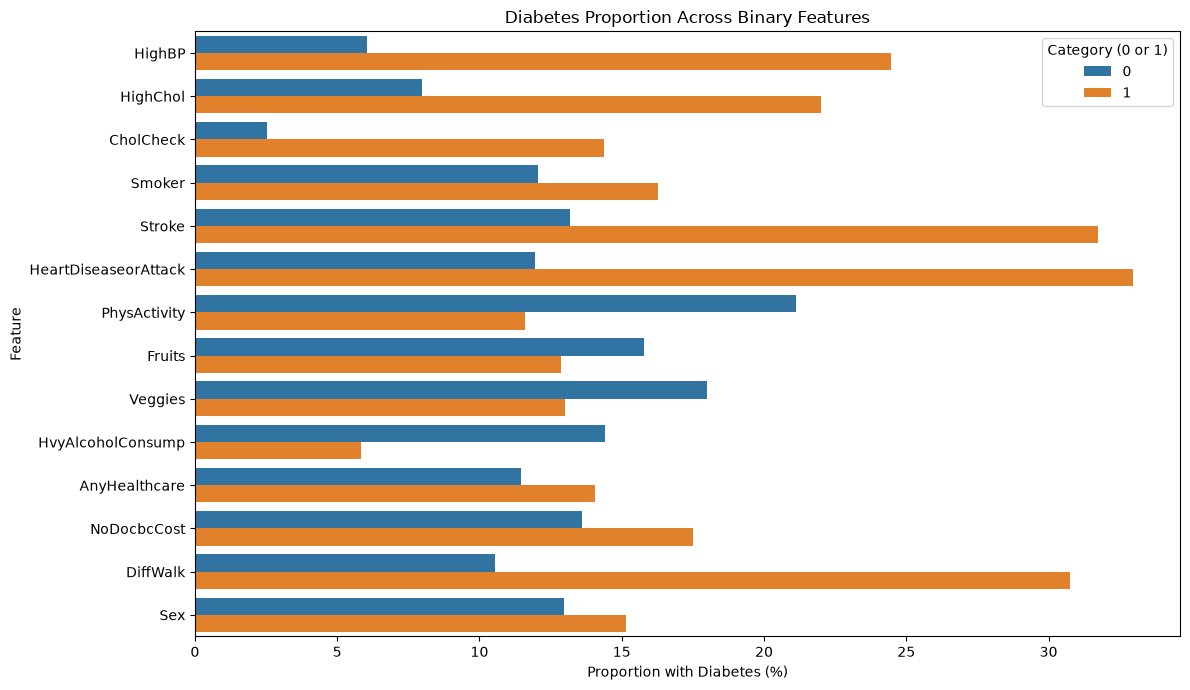

In [38]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=binary_summary,
    x="Diabetes (%)",
    y="Feature",
    hue="Category"
)

plt.title("Diabetes Proportion Across Binary Features")
plt.xlabel("Proportion with Diabetes (%)")
plt.ylabel("Feature")
plt.legend(title="Category (0 or 1)")
plt.tight_layout()
plt.show()

## Step 3 – Create TRAIN and TEST

- Split X and y into TRAIN and TEST.
- Use `stratify=y` so TRAIN and TEST have approximately the same proportion of class 0 and class 1.
- Keep TEST separate until evaluation. Do **not** balance or resample TEST.

*Related question: Q4*

In [43]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (202944, 21)
Test set: (50736, 21)


In [44]:
# Compare class distributions in training and test sets
class_comparison = pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100
})

display(class_comparison.round(2))

,Train (%),Test (%)
Diabetes_binary,,
0.0,86.07,86.07
1.0,13.93,13.93


## Step 4 – Prepare the features

- Choose preprocessing based on whether a feature is numerical, binary categorical, or ordered categorical, and briefly justify how each type is represented.
- Use a `Pipeline` / `ColumnTransformer` where appropriate.
- Anything learned from the data during preprocessing must be learned from TRAIN only and then applied to TEST.

## Step 5 – Train Logistic Regression

- Fit the complete Pipeline (preprocessing + Logistic Regression) using TRAIN.
- Use `model.predict(X_test)` to obtain predicted classes.
- Use `model.predict_proba(X_test)[:, 1]` to obtain predicted probabilities for class 1.

## Step 6 – Evaluate the model

Evaluate the model on TEST using:

- confusion matrix
- accuracy
- precision
- recall
- F1 score

Explain what a false positive and a false negative mean for this diabetes problem. Do not judge the model from accuracy alone.

*Related question: Q5*

## Step 7 – Probability and threshold

Use the predicted probabilities to compare two decision thresholds: **0.50** and **0.40**.

- For each threshold, calculate the confusion matrix, precision and recall (plus accuracy, F1, FP and FN for the table below).
- Explain what happened to false positives, false negatives, precision and recall.
- Explain what did **not** change when only the threshold changed.

| Threshold | Accuracy | Precision | Recall | F1 | False positives | False negatives |
|---|---|---|---|---|---|---|
| 0.50 | | | | | | |
| 0.40 | | | | | | |

*Related question: Q6*

## Step 8 – Conclusion

- Summarize the most important things learned from the EDA and the Logistic Regression results.
- Give at least two limitations of this analysis.
- Do not interpret an association as evidence that a feature causes diabetes.

*Related question: Q7*